In [7]:
pip install ultralytics grad-cam

Note: you may need to restart the kernel to use updated packages.


## **Dataset Preparation Utilities**

In [ ]:
import os
import sys
import glob
import cv2
import yaml
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO
from huggingface_hub import HfApi, hf_hub_download

# ==================== CONFIGURATION ====================
KAGGLE_INPUT_DIR = Path("/kaggle/input")
DATASET_NAME = "uav-detection-dataset"
DATASET_PATH = KAGGLE_INPUT_DIR / "datasets" / "hannusiaknysh" / DATASET_NAME / "extracted_dataset"
WORKING_DIR = Path("/kaggle/working")
OUTPUT_DIR   = str(WORKING_DIR / "runs" / "detect")  # ← додай це

# Secure Credentials Loading
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    REPO_ID = user_secrets.get_secret("REPO_ID")
    HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
except Exception as e:
    REPO_ID = os.getenv("REPO_ID")
    HF_TOKEN = os.getenv("HF_TOKEN")
    if not REPO_ID or not HF_TOKEN:
        print(f"[INFO] Could not load Kaggle Secrets. Using environment variables or skipping cloud upload. Error: {e}")

DEFAULT_MODEL_TYPE = "yolo26n.pt"
IMGSZ = 1280
EPOCHS = 50
BATCH_SIZE = 8
PATIENCE = 15

In [9]:
def safe_symlink(src: Path, dst: Path):
    """Creates a symlink, unlinking any existing symlink or file at destination first."""
    if dst.is_symlink() or dst.exists():
        try:
            dst.unlink()
        except OSError:
            return
    try:
        os.symlink(src, dst)
    except FileExistsError:
        pass

def prepare_yolo_dataset(dataset_path: Path, working_dir: Path, run_name: str, use_negatives: bool) -> Path:
    """Prepares isolated directories and creates symlinks for images and labels."""
    print(f"\n[DATA PREPARATION] Setting up dataset directories for run: {run_name}")
    
    run_data_dir = working_dir / f"yolo_dataset_{run_name}"
    
    # 1. CHANGED: Added "test" to the splits directory creation list
    for split in ["train", "val", "test"]:
        (run_data_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (run_data_dir / "labels" / split).mkdir(parents=True, exist_ok=True)
        
    def process_split(split_name: str):
        # 1. Symlink positive samples
        pos_dir = dataset_path / split_name / "RAW_POSITIVES"
        linked_pos_count = 0
        if pos_dir.exists():
            for jpg_path in pos_dir.glob("*.jpg"):
                txt_path = jpg_path.with_suffix(".txt")
                if txt_path.exists():
                    dest_img = run_data_dir / "images" / split_name / jpg_path.name
                    dest_lbl = run_data_dir / "labels" / split_name / txt_path.name
                    
                    safe_symlink(jpg_path, dest_img)
                    safe_symlink(txt_path, dest_lbl)
                    linked_pos_count += 1

        # 2. Symlink negative samples (only if enabled for this run)
        linked_neg_count = 0
        if use_negatives:
            neg_dir = dataset_path / split_name / "RAW_NEGATIVES"
            if neg_dir.exists():
                for jpg_path in neg_dir.glob("*.jpg"):
                    dest_img = run_data_dir / "images" / split_name / jpg_path.name
                    safe_symlink(jpg_path, dest_img)
                    linked_neg_count += 1

        print(f"[{split_name.upper()}] Symlinked {linked_pos_count:,} positives and {linked_neg_count:,} negatives.")

    # 2. CHANGED: Process all three splits including test
    process_split("train")
    process_split("val")
    process_split("test")

    # Generate isolated dataset YAML file
    # 3. CHANGED: Added the "test" path entry to yaml_data
    yaml_data = {
        "path": str(run_data_dir.resolve()),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": {0: "drone"}
    }
    
    yaml_path = working_dir / f"dataset_{run_name}.yaml"
    with open(yaml_path, "w") as f:
        yaml.dump(yaml_data, f, default_flow_style=False)
        
    print(f"[DATA PREPARATION] Created YAML configuration at: {yaml_path}")
    return yaml_path

### **Training and Upload Pipeline**

In [10]:
def find_run_best_weights(working_dir: Path, run_name: str) -> Path:
    """Dynamically locates the best weights file for a specific run name."""
    # Шукаємо в OUTPUT_DIR де реально зберігається модель
    search_pattern = str(Path(OUTPUT_DIR) / f"{run_name}*" / "weights" / "best.pt")
    found_weights = sorted(glob.glob(search_pattern, recursive=True))
    if found_weights:
        best_weights = Path(found_weights[-1])
        print(f"[INFO] Dynamically detected best weights at: {best_weights.resolve()}")
        return best_weights
    else:
        best_weights = Path(OUTPUT_DIR) / run_name / "weights" / "best.pt"
        print(f"[WARNING] Dynamic search failed. Defaulting to: {best_weights.resolve()}")
        return best_weights

def upload_checkpoint_to_hf(weights_path: Path, run_name: str):
    """Uploads model weights to Hugging Face repository under an isolated path."""
    if REPO_ID and HF_TOKEN and weights_path.exists():
        print(f"[HF UPLOAD] Uploading checkpoint for {run_name} to Hugging Face...")
        try:
            api = HfApi(token=HF_TOKEN)
            api.upload_file(
                path_or_fileobj=str(weights_path),
                path_in_repo=f"models/yolo26n_{run_name}_best.pt",
                repo_id=REPO_ID,
                repo_type="dataset"
            )
            print("[SUCCESS] Checkpoint successfully uploaded to Hugging Face.")
        except Exception as e:
            print(f"[WARNING] Hugging Face upload failed: {e}")
    else:
        print("[INFO] Hugging Face upload skipped: credentials or weights file missing.")

def run_yolo_training(yaml_path: Path, run_name: str) -> Path:
    """Initializes and runs the training pipeline for a given run configuration."""
    print("\n" + "="*80)
    print(f"STARTING YOLO TRAINING RUN: {run_name.upper()}")
    print("="*80)
    print(f"Loading weights: {DEFAULT_MODEL_TYPE}")

    model = YOLO(DEFAULT_MODEL_TYPE)

    results = model.train(
        data=str(yaml_path),   # ← використовуємо yaml_path що передається
                               #   а не глобальний DATASET_YAML
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        device=0,
        optimizer="auto",      # ← явно для читабельності

        # Аугментації вимкнені
        mosaic=0.0,
        mixup=0.0,
        copy_paste=0.0,
        scale=0.0,
        fliplr=0.0,
        degrees=0.0,
        shear=0.0,
        translate=0.0,
        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.0,

        # Режим
        rect=True,
        cache="disk",
        workers=2,
        seed=42,
        deterministic=True,
        patience=PATIENCE,

        # Збереження — run_name як назва папки
        project=OUTPUT_DIR,
        name=run_name,         # ← використовуємо run_name а не хардкод "final_model"
        exist_ok=True,
        save=True,
        plots=True,
    )

    best_weights = find_run_best_weights(WORKING_DIR, run_name)

    if results is not None and hasattr(results, "results_dict"):
        metrics = results.results_dict
        print("\n" + "="*50)
        print(f"METRICS REPORT ({run_name.upper()})")
        print("="*50)
        print(f"Precision (P):   {metrics.get('metrics/precision(B)', 0.0):.4f}")
        print(f"Recall (R):      {metrics.get('metrics/recall(B)', 0.0):.4f}")
        print(f"mAP50:           {metrics.get('metrics/mAP50(B)', 0.0):.4f}")
        print(f"mAP50-95:        {metrics.get('metrics/mAP50-95(B)', 0.0):.4f}")
        print("="*50)

    upload_checkpoint_to_hf(best_weights, run_name)
    return best_weights

def evaluate_model(weights_path: Path, yaml_path: Path, run_name: str):
    """Evaluates the trained model on the 'test' split and prints metrics."""
    print("\n" + "="*80)
    print(f"STARTING YOLO EVALUATION ON TEST DATA: {run_name.upper()}")
    print("="*80)
    print(f"Loading weights from: {weights_path.resolve()}")
    
    # Load the trained model weights
    model = YOLO(str(weights_path))
    
    # Run validation on the test split
    # 'split="test"' forces the model to use the test paths from your dataset YAML
    metrics = model.val(
        data=str(yaml_path),
        split="test",       # Explicitly evaluate on the test subset
        imgsz=1280,         # Match training resolution
        batch=8,            # Match training batch
        device=0,           # Match training GPU device
        rect=True,          # Match training rectangular inference
        project=str(OUTPUT_DIR),
        name=f"{run_name}_test_evaluation",
        exist_ok=True,
        save=True,          # Save predicted bounding boxes
        plots=True          # Generate validation plots (PR curves, Confusion Matrix, etc.)
    )
    
    # Extract and safely print test metrics
    if metrics is not None and hasattr(metrics, 'results_dict'):
        metrics_dict = metrics.results_dict
        print("\n" + "="*50)
        print(f"TEST DATA METRICS REPORT ({run_name.upper()})")
        print("="*50)
        print(f"Precision (P):              {metrics_dict.get('metrics/precision(B)', 0.0):.4f}")
        print(f"Recall (R):                 {metrics_dict.get('metrics/recall(B)', 0.0):.4f}")
        print(f"mAP50:                      {metrics_dict.get('metrics/mAP50(B)', 0.0):.4f}")
        print(f"mAP50-95:                   {metrics_dict.get('metrics/mAP50-95(B)', 0.0):.4f}")
        print("="*50)
        
    return metrics

### **EigenCAM Visualization Utilities**

In [11]:
def load_eval_model(weights_path: str, device: torch.device):
    """Loads a trained YOLO model and prepares its PyTorch module for inference."""
    model = YOLO(weights_path)
    pytorch_model = model.model
    pytorch_model.eval()
    pytorch_model.to(device)
    print(f"[EVAL] Model loaded from: {weights_path}")
    print(f"[EVAL] Parameters: {sum(p.numel() for p in pytorch_model.parameters()):,}")
    return model, pytorch_model

def find_sppf_layer(pytorch_model):
    """Dynamically scans backbones to isolate the SPPF layer."""
    for i, layer in enumerate(pytorch_model.model):
        if "SPPF" in type(layer).__name__:
            print(f"[EVAL] SPPF layer dynamically found at index {i}")
            return layer, i
    print("[WARNING] SPPF layer not found automatically. Using fallback index 9")
    return pytorch_model.model[9], 9

def run_eigencam_gradcam(pytorch_model, target_layer, img_tensor):
    """EigenCAM implementation relying on pytorch-grad-cam library wrapper."""
    try:
        from pytorch_grad_cam import EigenCAM

        class YOLOWrapper(torch.nn.Module):
            def __init__(self, model):
                super().__init__()
                self.model = model
            def forward(self, x):
                output = self.model(x)
                if isinstance(output, (list, tuple)):
                    preds = output[0] if isinstance(output[0], torch.Tensor) else output
                    if preds.dim() == 3:
                        return preds[:, :, 4:5].squeeze(-1)
                    return preds
                return output

        wrapped = YOLOWrapper(pytorch_model)
        cam = EigenCAM(model=wrapped, target_layers=[target_layer])
        with torch.no_grad():
            grayscale_cam = cam(input_tensor=img_tensor)
        return grayscale_cam[0]
    except Exception:
        return None

def manual_eigencam(pytorch_model, target_layer, img_tensor):
    """Manual SVD-based EigenCAM fallback when third-party wrappers fail."""
    activations = {}
    def hook(model, input, output):
        activations["feat"] = output.detach()

    handle = target_layer.register_forward_hook(hook)
    with torch.no_grad():
        _ = pytorch_model(img_tensor)
    handle.remove()

    feat = activations["feat"].cpu().squeeze(0).numpy()  # Shape: (C, H, W)
    reshaped = feat.reshape(feat.shape[0], -1)           # Shape: (C, H*W)
    _, _, Vt = np.linalg.svd(reshaped, full_matrices=False)
    
    cam_map = Vt[0].reshape(feat.shape[1], feat.shape[2])
    if cam_map.mean() < 0:
        cam_map = -cam_map

    cam_map = np.maximum(cam_map, 0)
    cam_map -= cam_map.min()
    if cam_map.max() > 0:
        cam_map /= cam_map.max()
    return cam_map

def preprocess_image(img_path: str, device: torch.device):
    """Rescales raw validation frames and constructs PyTorch tensors."""
    img = cv2.imread(img_path)
    if img is None:
        return None, None, None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (640, 640))
    tensor = torch.from_numpy(img_resized).permute(2, 0, 1).float() / 255.0
    tensor = tensor.unsqueeze(0).to(device)
    return img_rgb, img_resized, tensor

def overlay_heatmap(img_rgb, cam_map, alpha=0.4):
    """Overlays generated attention maps onto target images."""
    h, w = img_rgb.shape[:2]
    heatmap = cv2.resize(cam_map, (w, h))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img_rgb, 1 - alpha, heatmap_color, alpha, 0)

def get_detections(model, img_path: str, conf: float):
    """Executes standard YOLO inference to retrieve bounding boxes."""
    results = model(img_path, conf=conf, verbose=False)
    boxes = []
    if results and results[0].boxes is not None:
        for box in results[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            conf_val = float(box.conf[0])
            boxes.append((int(x1), int(y1), int(x2), int(y2), conf_val))
    return boxes

def analyze_single_image(model, pytorch_model, target_layer, img_path: str, device: torch.device, save_path: Path, conf_thresh: float):
    """Renders visual layout displaying predictions side-by-side with CAM mappings."""
    img_rgb, _, tensor = preprocess_image(img_path, device)
    if img_rgb is None:
        return None

    cam_map = run_eigencam_gradcam(pytorch_model, target_layer, tensor)
    if cam_map is None:
        cam_map = manual_eigencam(pytorch_model, target_layer, tensor)

    overlay = overlay_heatmap(img_rgb, cam_map)
    boxes = get_detections(model, img_path, conf=conf_thresh)

    overlay_with_boxes = overlay.copy()
    for (x1, y1, x2, y2, conf_val) in boxes:
        cv2.rectangle(overlay_with_boxes, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(overlay_with_boxes, f"drone {conf_val:.2f}",
                    (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(f"EigenCAM Activation Map — {Path(img_path).name}", fontsize=11, fontweight="bold")

    axes[0].imshow(img_rgb)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(overlay)
    axes[1].set_title("EigenCAM Attention")
    axes[1].axis("off")

    axes[2].imshow(overlay_with_boxes)
    axes[2].set_title(f"Predictions ({len(boxes)} found)")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()

    return len(boxes)

### **Main Orchestration Functions**

In [12]:
def run_full_pipeline(use_negatives: bool, run_name: str) -> Path:
    """Executes the setup, training, and subsequent test evaluation pipeline."""
    if not DATASET_PATH.exists():
        raise FileNotFoundError(f"Dataset path {DATASET_PATH} does not exist.")
        
    # Prepare the dataset splits and write YAML config
    yaml_path = prepare_yolo_dataset(DATASET_PATH, WORKING_DIR, run_name, use_negatives)
    
    # Train the model and get the best weights path
    best_weights = run_yolo_training(yaml_path, run_name)
    
    # Run evaluation on the test split right after training
    evaluate_model(best_weights, yaml_path, run_name)
    
    return best_weights

def run_shortcut_analysis(weights_path: str, val_dir: str, output_dir_path: str, run_name: str, n_images: int = 15, conf_thresh: float = 0.25):
    """Executes model diagnostics by projecting CAM maps onto sampled verification frames."""
    print("\n" + "="*80)
    print(f"STARTING SHORTCUT ANALYSIS FOR: {run_name.upper()}")
    print("="*80)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    output_dir = Path(output_dir_path) / run_name
    output_dir.mkdir(exist_ok=True, parents=True)

    resolved_weights_path = None
    hf_file_name = f"models/yolo26n_{run_name}_best.pt"

    # 1. Try pulling from Hugging Face Storage first
    if REPO_ID and HF_TOKEN:
        print(f"[INFO] Attempting download from HF Hub: {hf_file_name}")
        try:
            downloaded = hf_hub_download(
                repo_id=REPO_ID,
                filename=hf_file_name,
                repo_type="dataset",
                token=HF_TOKEN
            )
            resolved_weights_path = Path(downloaded)
            print(f"[SUCCESS] Weights downloaded to secure cache: {resolved_weights_path}")
        except Exception as e:
            print(f"[WARNING] Could not fetch from Hugging Face Hub: {e}")

    # 2. Disk fallbacks
    if resolved_weights_path is None or not resolved_weights_path.exists():
        direct_path = Path(weights_path)
        if direct_path.exists():
            resolved_weights_path = direct_path
        else:
            print("[INFO] Fallback searching local directories...")
            search_pattern = f"/kaggle/working/runs/detect/yolo26_shortcut_analysis/{run_name}*/weights/best.pt"
            found_weights = sorted(glob.glob(search_pattern, recursive=True))
            if found_weights:
                resolved_weights_path = Path(found_weights[-1])
                print(f"[SUCCESS] Local checkpoint located: {resolved_weights_path}")
            else:
                print("❌ [ERROR] Could not resolve any valid 'best.pt' file.")
                return

    # Load evaluated structures
    model, pytorch_model = load_eval_model(str(resolved_weights_path), device)
    target_layer, _ = find_sppf_layer(pytorch_model)

    all_images = glob.glob(str(Path(val_dir) / "*.jpg"))
    if not all_images:
        print(f"❌ [ERROR] Verification folder is empty: {val_dir}")
        return

    random.seed(42)
    selected_images = random.sample(all_images, min(n_images, len(all_images)))
    print(f"[INFO] Sampling {len(selected_images)} frames for analysis.")

    detection_counts = []
    for i, img_path in enumerate(tqdm(selected_images, desc="Generating Visualizations")):
        save_file_path = output_dir / f"cam_{i:03d}_{Path(img_path).stem}.png"
        n_dets = analyze_single_image(
            model, pytorch_model, target_layer,
            img_path, device, save_file_path, conf_thresh
        )
        if n_dets is not None:
            detection_counts.append(n_dets)

    # Plot metrics without overwriting previous runs
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(len(detection_counts)), detection_counts, color="#4A90D9")
    ax.set_title(f"Detections Per Frame Summary — {run_name}")
    ax.set_xlabel("Sample Frame Index")
    ax.set_ylabel("Bounding Box Count")
    ax.axhline(y=1, color="red", linestyle="--", label="Expected (1)")
    ax.grid(True, alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "detection_summary.png", dpi=120)
    plt.show()
    plt.close()

    print("\n" + "="*50)
    print(f"ANALYSIS REPORT: {run_name.upper()}")
    print("="*50)
    print(f"Frames Analyzed:            {len(selected_images)}")
    print(f"Average Detections/Frame:   {np.mean(detection_counts):.2f}")
    print(f"Missed Objects:             {sum(1 for d in detection_counts if d == 0)}")
    print(f"Artifacts Saved To:         {output_dir.resolve()}")
    print("="*50)

## **Execution Block**


[DATA PREPARATION] Setting up dataset directories for run: run_positives_only
[TRAIN] Symlinked 8,177 positives and 0 negatives.
[VAL] Symlinked 6,035 positives and 0 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_run_positives_only.yaml

STARTING YOLO TRAINING RUN: RUN_POSITIVES_ONLY
Loading weights: yolo26n.pt
Ultralytics 8.4.68 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_run_positives_only.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING SHORTCUT ANALYSIS FOR: RUN_POSITIVES_ONLY
[INFO] Attempting download from HF Hub: models/yolo26n_run_positives_only_best.pt


models/yolo26n_run_positives_only_best.p(…):   0%|          | 0.00/5.50M [00:00<?, ?B/s]

[SUCCESS] Weights downloaded to secure cache: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/d231232d39cb04812c8ce445d46cfd16511b6027/models/yolo26n_run_positives_only_best.pt
[EVAL] Model loaded from: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/d231232d39cb04812c8ce445d46cfd16511b6027/models/yolo26n_run_positives_only_best.pt
[EVAL] Parameters: 2,504,190
[EVAL] SPPF layer dynamically found at index 9
[INFO] Sampling 10 frames for analysis.


Generating Visualizations:   0%|          | 0/10 [00:00<?, ?it/s]

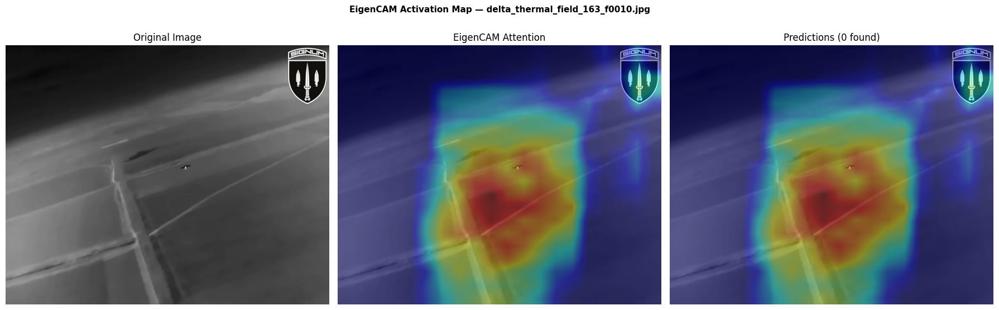

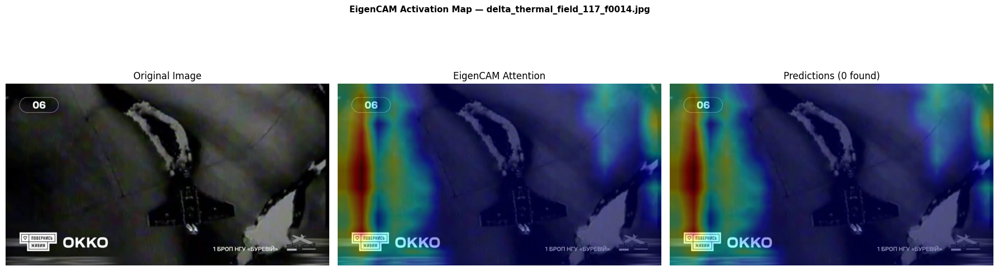

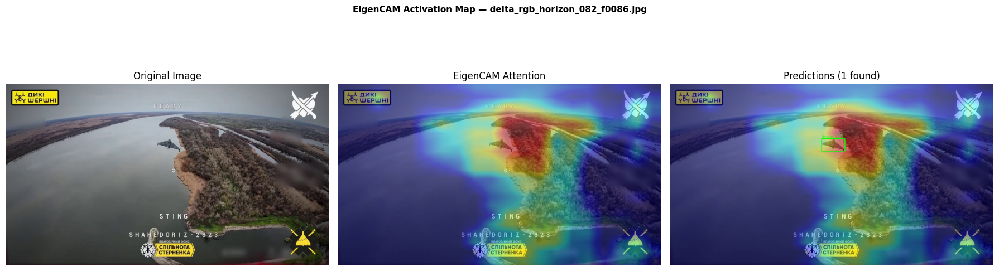

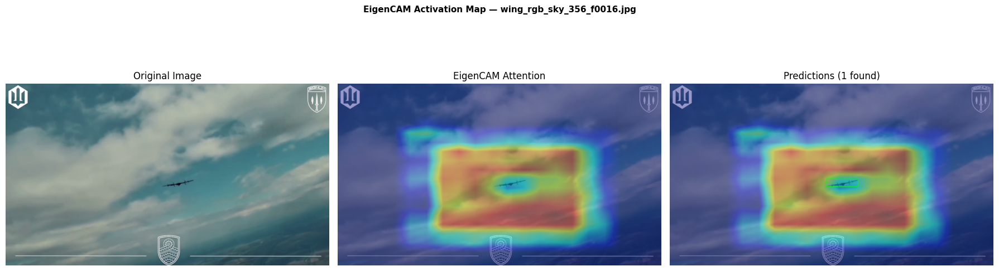

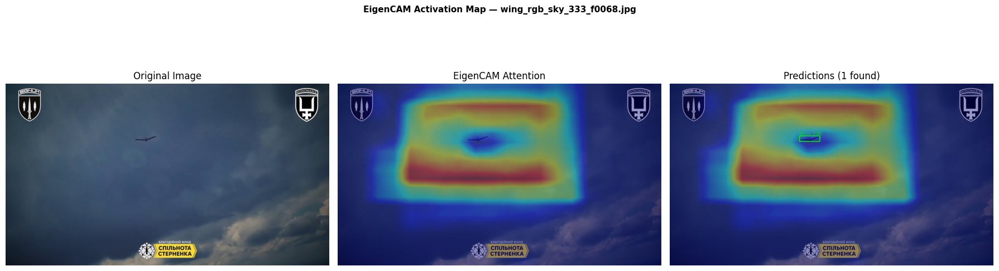

...

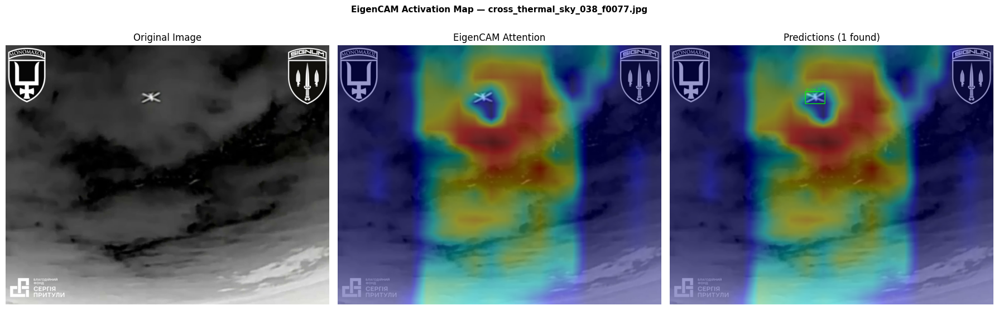

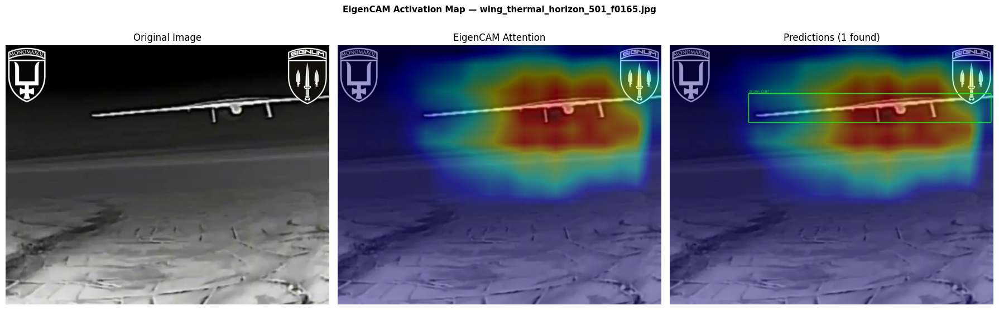

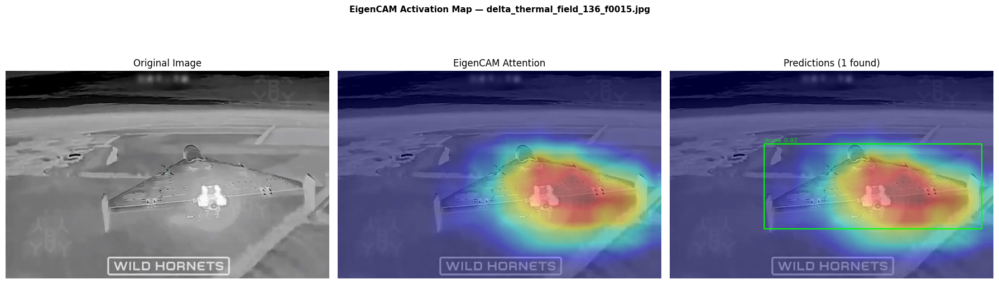

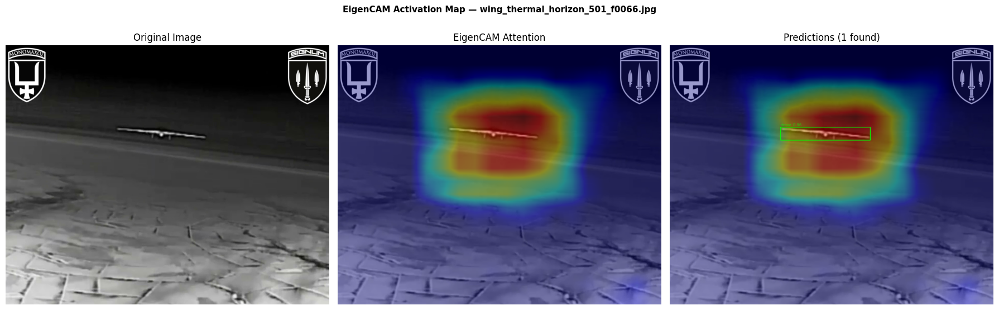

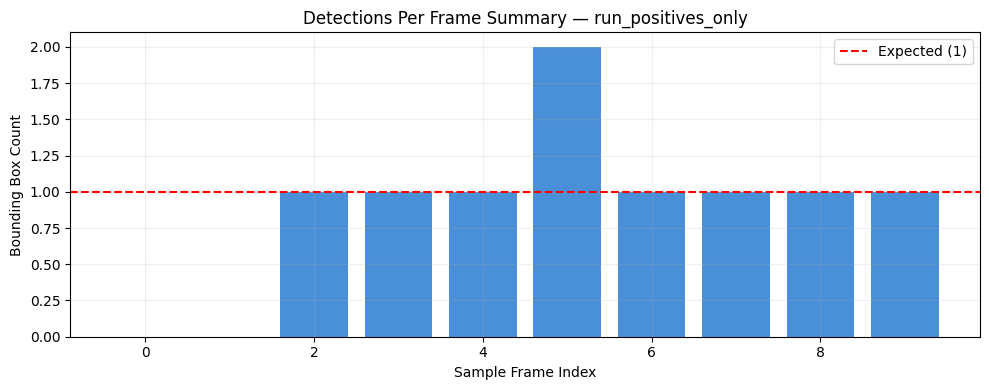


ANALYSIS REPORT: RUN_POSITIVES_ONLY
Frames Analyzed:            10
Average Detections/Frame:   0.90
Missed Objects:             2
Artifacts Saved To:         /kaggle/working/analysis_results/run_positives_only


In [7]:
# ==========================================
# RUN 1: Positives-Only Dataset
# ==========================================
run_name_1 = "run_positives_only"

# 1. Train Run 1
best_weights_1 = run_full_pipeline(use_negatives=False, run_name=run_name_1)

# 2. Analyze Run 1
val_dir_1 = WORKING_DIR / f"yolo_dataset_{run_name_1}" / "images" / "val"
run_shortcut_analysis(
    weights_path=str(best_weights_1),
    val_dir=str(val_dir_1),
    output_dir_path="/kaggle/working/analysis_results",
    run_name=run_name_1,
    n_images=10,
    conf_thresh=0.25
)


[DATA PREPARATION] Setting up dataset directories for run: run_with_negatives
[TRAIN] Symlinked 8,177 positives and 810 negatives.
[VAL] Symlinked 6,035 positives and 1,047 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_run_with_negatives.yaml

STARTING YOLO TRAINING RUN: RUN_WITH_NEGATIVES
Loading weights: yolo26n.pt
Ultralytics 8.4.68 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_run_with_negatives.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, 

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING SHORTCUT ANALYSIS FOR: RUN_WITH_NEGATIVES
[INFO] Attempting download from HF Hub: models/yolo26n_run_with_negatives_best.pt


models/yolo26n_run_with_negatives_best.p(…):   0%|          | 0.00/5.50M [00:00<?, ?B/s]

[SUCCESS] Weights downloaded to secure cache: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Model loaded from: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Parameters: 2,504,190
[EVAL] SPPF layer dynamically found at index 9
[INFO] Sampling 10 frames for analysis.


Generating Visualizations:   0%|          | 0/10 [00:00<?, ?it/s]

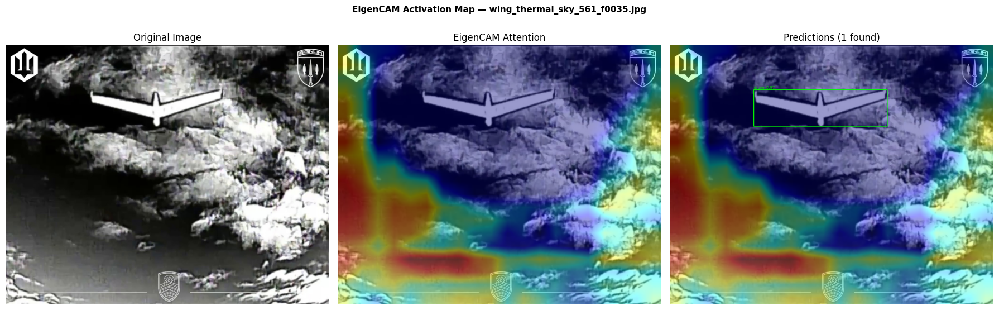

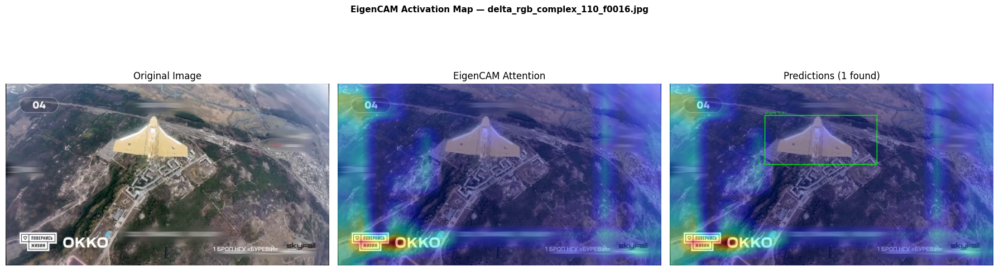

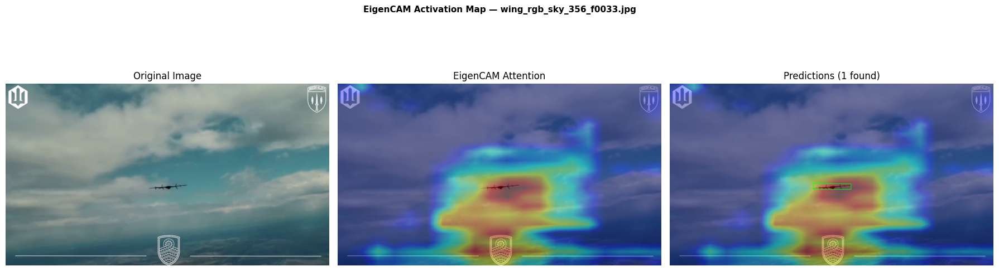

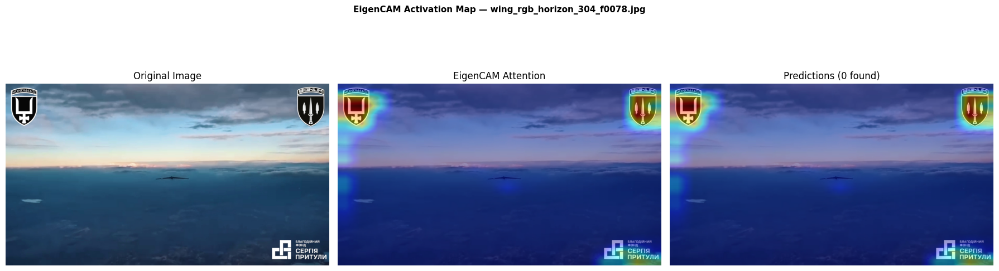

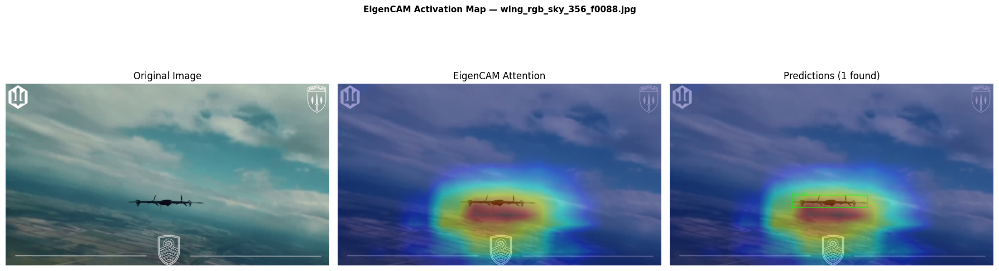

...

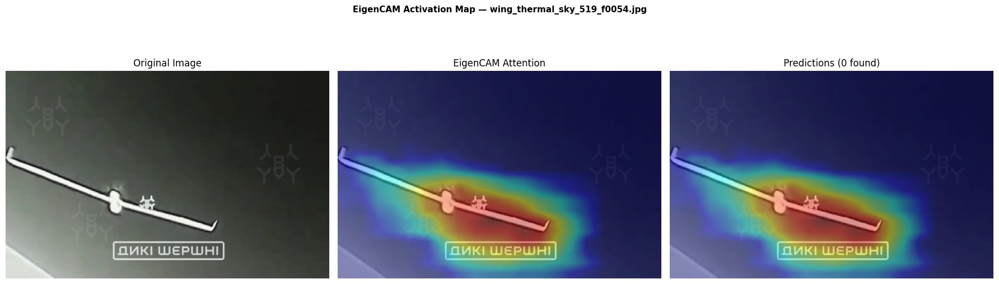

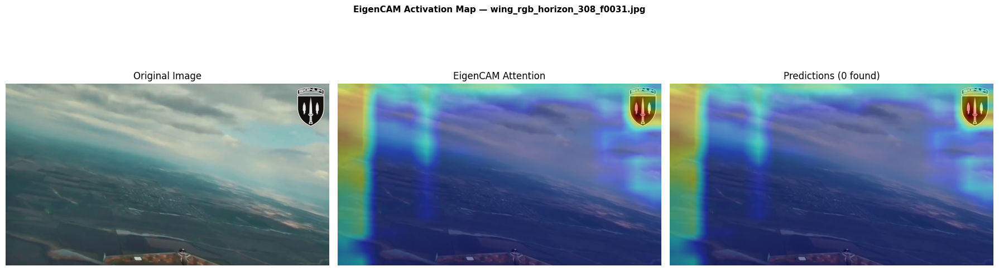

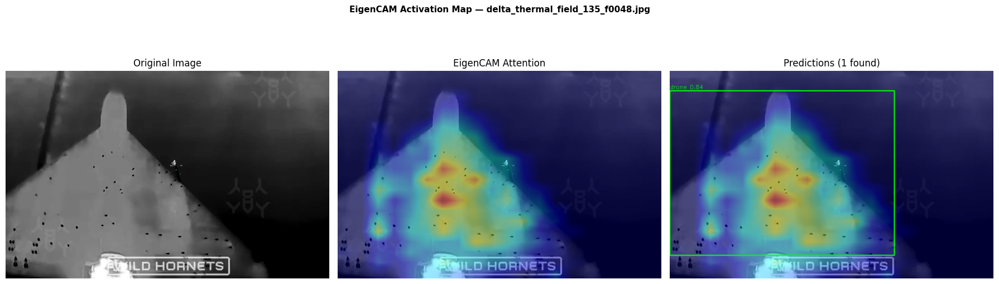

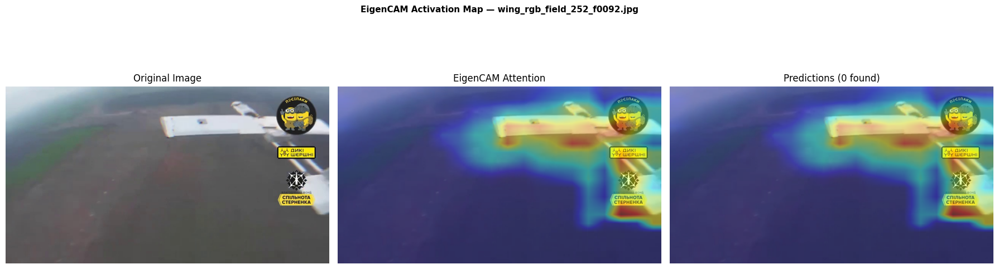

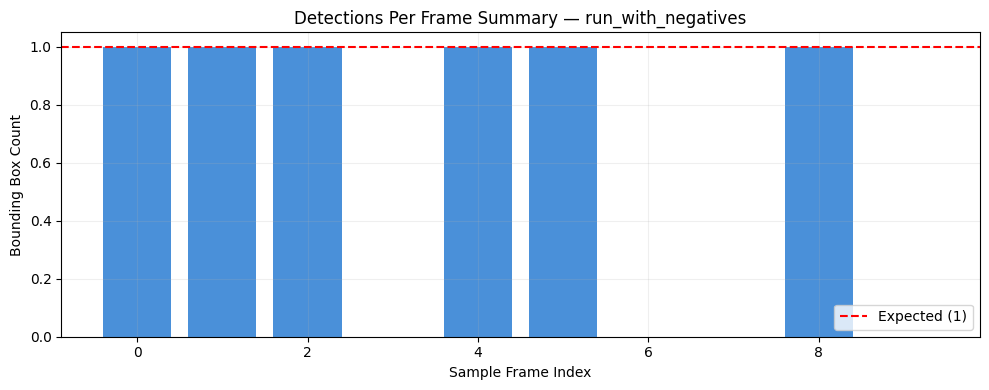


ANALYSIS REPORT: RUN_WITH_NEGATIVES
Frames Analyzed:            10
Average Detections/Frame:   0.60
Missed Objects:             4
Artifacts Saved To:         /kaggle/working/analysis_results/run_with_negatives


In [8]:
# ==========================================
# RUN 2: Positives + Negatives Dataset
# ==========================================
run_name_2 = "run_with_negatives"

# 1. Train Run 2
best_weights_2 = run_full_pipeline(use_negatives=True, run_name=run_name_2)

# 2. Analyze Run 2
val_dir_2 = WORKING_DIR / f"yolo_dataset_{run_name_2}" / "images" / "val"
run_shortcut_analysis(
    weights_path=str(best_weights_2),
    val_dir=str(val_dir_2),
    output_dir_path="/kaggle/working/analysis_results",
    run_name=run_name_2,
    n_images=10,
    conf_thresh=0.25
)


STARTING SHORTCUT ANALYSIS FOR: RUN_WITH_NEGATIVES
[INFO] Attempting download from HF Hub: models/yolo26n_run_with_negatives_best.pt
[SUCCESS] Weights downloaded to secure cache: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Model loaded from: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Parameters: 2,504,190
[EVAL] SPPF layer dynamically found at index 9
[INFO] Sampling 20 frames for analysis.


Generating Visualizations:   0%|          | 0/20 [00:00<?, ?it/s]

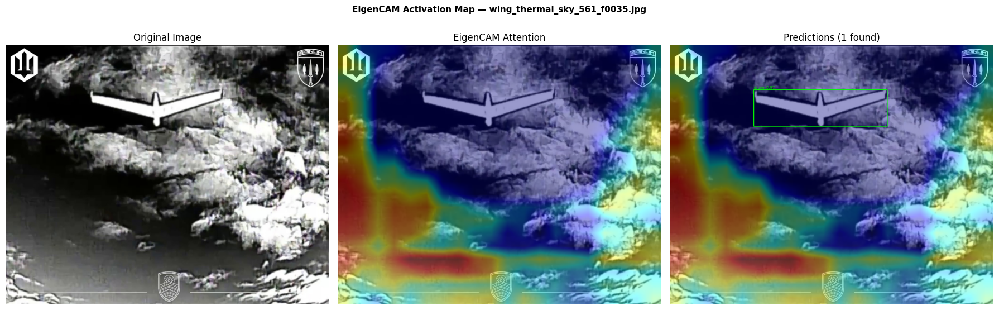

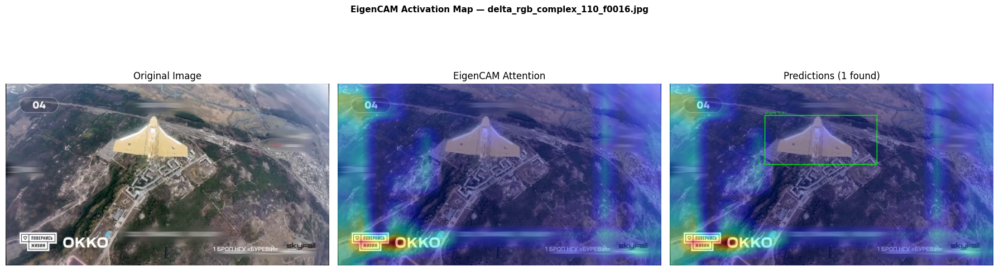

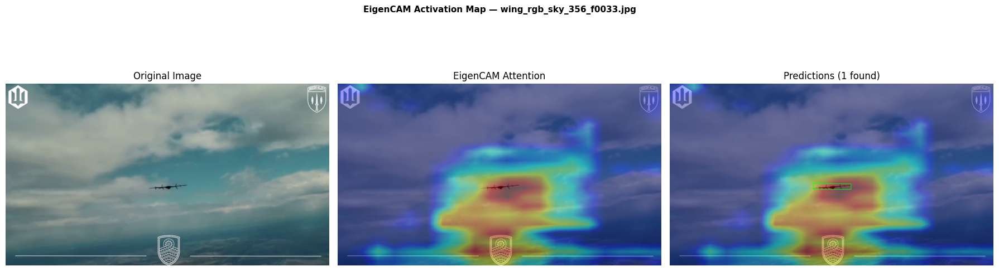

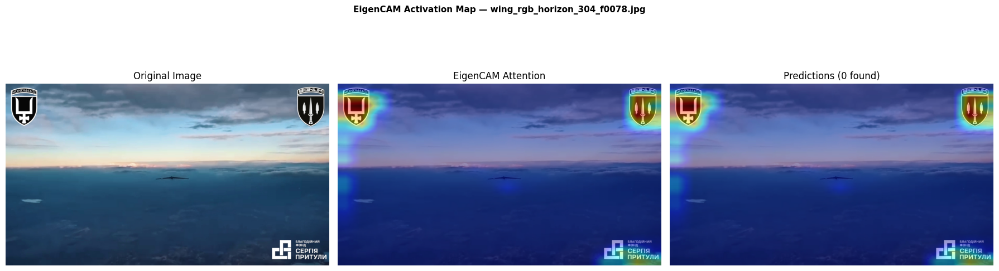

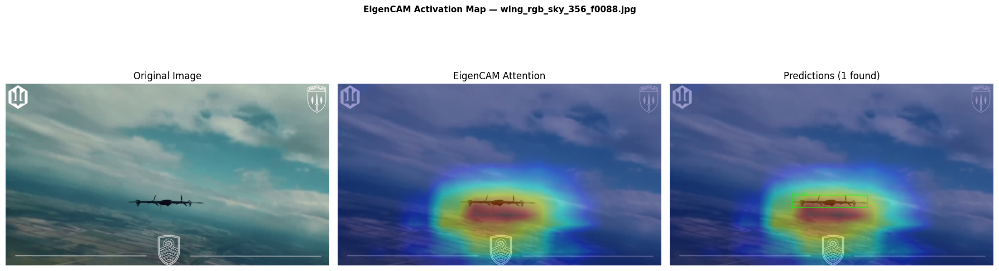

...

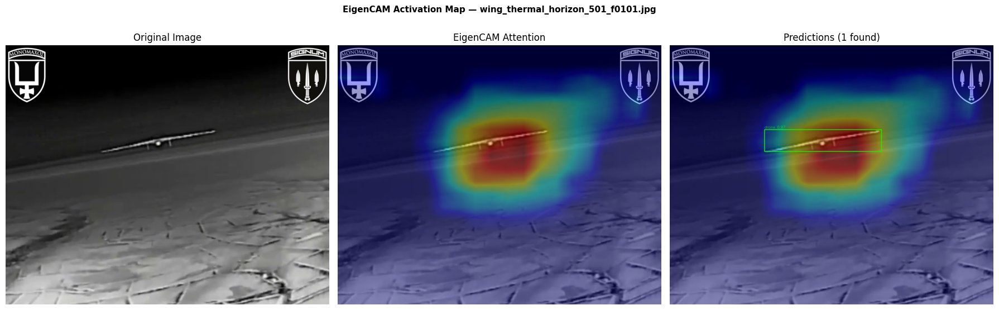

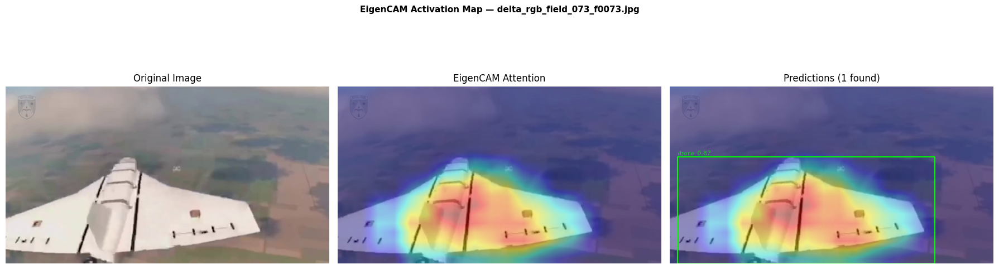

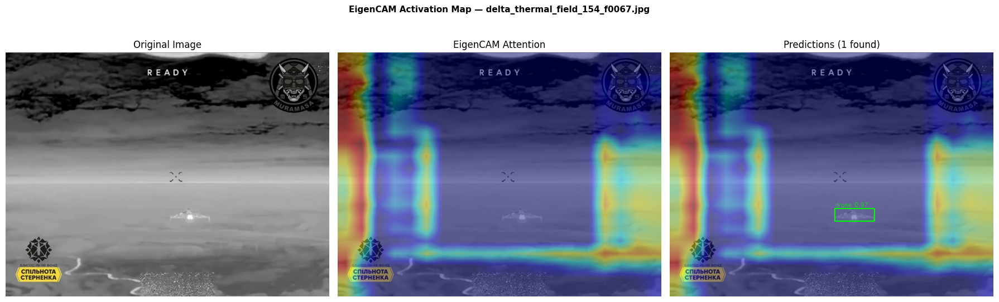

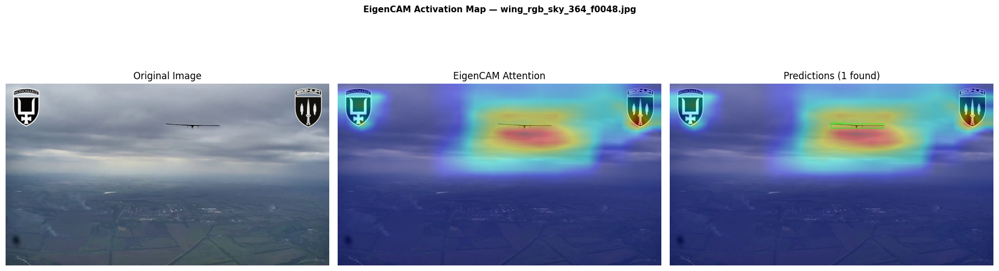

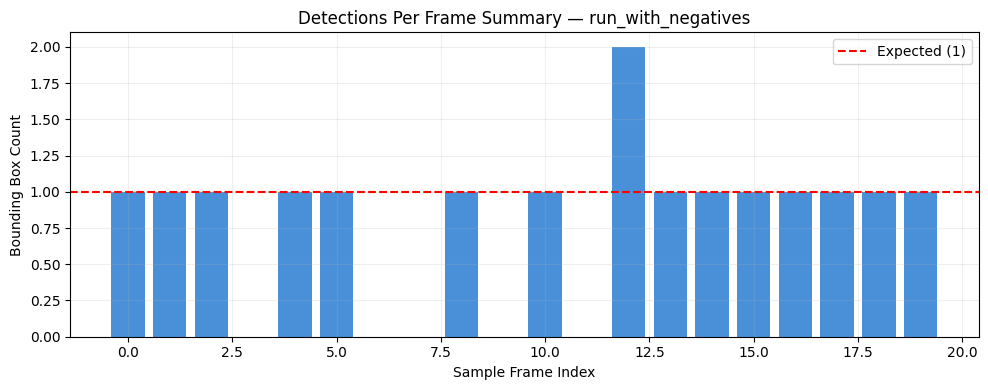


ANALYSIS REPORT: RUN_WITH_NEGATIVES
Frames Analyzed:            20
Average Detections/Frame:   0.80
Missed Objects:             5
Artifacts Saved To:         /kaggle/working/analysis_results/run_with_negatives


In [10]:
run_shortcut_analysis(
    weights_path=str(best_weights_2),
    val_dir=str(val_dir_2),
    output_dir_path="/kaggle/working/analysis_results",
    run_name=run_name_2,
    n_images=20,
    conf_thresh=0.25
)

In [2]:
"""
False Positive Mining — пошук найважчих негативів
==================================================
Завантажує ваги з HuggingFace, запускає інференс на всіх негативах
і знаходить кадри де модель дала false positive (детектувала дрон
там де його немає). Зберігає EigenCAM візуалізації для найважчих випадків.

Запуск:
    python fp_mining.py

Потребує в .env:
    HF_TOKEN=hf_...
    REPO_ID=hannusia123123/drone_dataset
"""

import os
import sys
import cv2
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download
from ultralytics import YOLO
from dotenv import load_dotenv

load_dotenv()

# ================= CONFIGURATION =================
REPO_ID = os.getenv("REPO_ID")
HF_TOKEN = os.getenv("HF_TOKEN") 

# ================= КОНФІГУРАЦІЯ =================
HF_TOKEN   = os.getenv("HF_TOKEN")
REPO_ID    = os.getenv("REPO_ID")                        # hannusia123123/drone_dataset
MODEL_FILE = "models/yolo26n_run_with_negatives_best.pt" # шлях всередині репо

NEGATIVES_DIR = Path(os.getenv("EXTRACTED_DATA_PATH")) / "train" / "RAW_NEGATIVES"
OUTPUT_DIR    = Path("fp_mining_results")

CONF_THRESH   = 0.25   # поріг впевненості для детекції
TOP_N         = 30     # скільки найважчих негативів зберегти з EigenCAM
# =================================================

OUTPUT_DIR.mkdir(exist_ok=True)


# -------------------------------------------------
# 1. Завантаження ваг з HuggingFace
# -------------------------------------------------
def download_weights() -> Path:
    print(f"Завантаження ваг з HuggingFace...")
    print(f"  Репо:  {REPO_ID}")
    print(f"  Файл:  {MODEL_FILE}")

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=MODEL_FILE,
        token=HF_TOKEN,
        repo_type="dataset",
        local_dir=Path("hf_weights"),
    )
    print(f"  Збережено: {local_path}")
    return Path(local_path)


# -------------------------------------------------
# 2. Інференс на всіх негативах
# -------------------------------------------------
def run_inference(model: YOLO, negatives_dir: Path) -> list[dict]:
    """
    Повертає список словників для кадрів де модель
    знайшла хоч одну детекцію (false positive).
    """
    all_images = sorted(negatives_dir.glob("*.jpg"))
    print(f"\nЗнайдено негативів: {len(all_images)}")
    print(f"Запускаємо інференс з conf={CONF_THRESH}...")

    false_positives = []

    for img_path in tqdm(all_images, desc="Інференс на негативах"):
        results = model(str(img_path), conf=CONF_THRESH, verbose=False)

        if results and results[0].boxes is not None and len(results[0].boxes) > 0:
            boxes = results[0].boxes
            max_conf = float(boxes.conf.max())

            false_positives.append({
                "path":     img_path,
                "n_dets":   len(boxes),
                "max_conf": max_conf,
                "boxes":    boxes.xyxy.cpu().numpy(),
                "confs":    boxes.conf.cpu().numpy(),
            })

    # Сортуємо за впевненістю — найгірші false positives першими
    false_positives.sort(key=lambda x: x["max_conf"], reverse=True)

    print(f"\nFalse positives знайдено: {len(false_positives)} / {len(all_images)}")
    if false_positives:
        print(f"Макс confidence: {false_positives[0]['max_conf']:.3f}")
        print(f"Мін confidence:  {false_positives[-1]['max_conf']:.3f}")

    return false_positives


# -------------------------------------------------
# 3. EigenCAM для одного зображення
# -------------------------------------------------
def get_eigencam(pytorch_model, target_layer, img_path: Path, device) -> np.ndarray:
    img = cv2.imread(str(img_path))
    if img is None:
        return None

    img_rgb     = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (640, 640))
    tensor      = torch.from_numpy(img_resized).permute(2, 0, 1).float() / 255.0
    tensor      = tensor.unsqueeze(0).to(device)

    activations = {}
    def hook(m, i, o):
        activations["feat"] = o.detach()
    handle = target_layer.register_forward_hook(hook)

    with torch.no_grad():
        _ = pytorch_model(tensor)
    handle.remove()

    feat = activations["feat"].cpu().squeeze(0).numpy()
    reshaped = feat.reshape(feat.shape[0], -1)
    _, _, Vt = np.linalg.svd(reshaped, full_matrices=False)
    cam = Vt[0].reshape(feat.shape[1], feat.shape[2])
    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam = (cam - cam.min()) / (cam.max() - cam.min())

    return cam, img_rgb


# -------------------------------------------------
# 4. Візуалізація одного false positive
# -------------------------------------------------
def visualize_fp(fp: dict, pytorch_model, target_layer,
                 device, save_path: Path):
    result = get_eigencam(pytorch_model, target_layer, fp["path"], device)
    if result is None:
        return

    cam, img_rgb = result
    h, w = img_rgb.shape[:2]

    # Накладаємо heatmap
    heatmap = cv2.resize(cam, (w, h))
    heatmap  = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_rgb, 0.6, heatmap_color, 0.4, 0)

    # Малюємо false positive bbox
    overlay_boxes = overlay.copy()
    for (x1, y1, x2, y2), conf in zip(fp["boxes"], fp["confs"]):
        cv2.rectangle(overlay_boxes,
                      (int(x1), int(y1)), (int(x2), int(y2)),
                      (255, 0, 0), 2)
        cv2.putText(overlay_boxes,
                    f"FP {conf:.2f}",
                    (int(x1), max(int(y1) - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(
        f"FALSE POSITIVE — {fp['path'].name}\n"
        f"Детекцій: {fp['n_dets']}  Макс conf: {fp['max_conf']:.3f}",
        fontsize=10, color="red"
    )

    axes[0].imshow(img_rgb)
    axes[0].set_title("Оригінал (дрону немає)")
    axes[0].axis("off")

    axes[1].imshow(overlay)
    axes[1].set_title("EigenCAM (на що дивиться модель)")
    axes[1].axis("off")

    axes[2].imshow(overlay_boxes)
    axes[2].set_title("False Positive bbox (червоний)")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.close()


# -------------------------------------------------
# 5. Зведений звіт
# -------------------------------------------------
def save_report(false_positives: list, total: int):
    report_path = OUTPUT_DIR / "fp_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write("FALSE POSITIVE MINING REPORT\n")
        f.write("=" * 60 + "\n\n")
        f.write(f"Всього негативів перевірено: {total}\n")
        f.write(f"False positives знайдено:    {len(false_positives)}\n")
        f.write(f"FP rate:                     "
                f"{len(false_positives)/total*100:.1f}%\n\n")
        f.write("ТОП FALSE POSITIVES (сортовано за confidence):\n")
        f.write("-" * 60 + "\n")
        for i, fp in enumerate(false_positives):
            f.write(f"{i+1:3d}. {fp['path'].name}\n")
            f.write(f"     Детекцій: {fp['n_dets']}  "
                    f"Макс conf: {fp['max_conf']:.4f}\n")
    print(f"\nЗвіт збережено: {report_path}")


# -------------------------------------------------
# MAIN
# -------------------------------------------------
def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Пристрій: {device}")

    # 1. Завантажуємо ваги
    weights_path = download_weights()

    # 2. Завантажуємо модель
    model = YOLO(str(weights_path))
    pytorch_model = model.model.to(device)
    pytorch_model.eval()

    # 3. Знаходимо SPPF шар
    target_layer = None
    for layer in pytorch_model.model:
        if "SPPF" in type(layer).__name__:
            target_layer = layer
            break
    if target_layer is None:
        target_layer = pytorch_model.model[9]
    print(f"Target layer: {type(target_layer).__name__}")

    # 4. Інференс на всіх негативах
    all_images   = list(NEGATIVES_DIR.glob("*.jpg"))
    total        = len(all_images)
    false_positives = run_inference(model, NEGATIVES_DIR)

    if not false_positives:
        print("\nFalse positives не знайдено — модель добре справляється з негативами!")
        return

    # 5. EigenCAM для топ-N найважчих
    top_fps = false_positives[:TOP_N]
    print(f"\nГенеруємо EigenCAM для топ-{len(top_fps)} false positives...")

    for i, fp in enumerate(tqdm(top_fps, desc="EigenCAM")):
        save_path = OUTPUT_DIR / f"fp_{i+1:03d}_conf{fp['max_conf']:.3f}_{fp['path'].stem}.png"
        visualize_fp(fp, pytorch_model, target_layer, device, save_path)

    # 6. Зведений звіт
    save_report(false_positives, total)

    print(f"\n{'='*50}")
    print(f"РЕЗУЛЬТАТИ")
    print(f"{'='*50}")
    print(f"FP rate: {len(false_positives)}/{total} = "
          f"{len(false_positives)/total*100:.1f}%")
    print(f"EigenCAM збережено: {OUTPUT_DIR}/")
    print(f"\nЦі кадри — найважчі негативи для твоєї моделі.")
    print(f"Саме їх потрібно додати в датасет для усунення shortcut learning.")


if __name__ == "__main__":
    main()

Пристрій: cpu
Завантаження ваг з HuggingFace...
  Репо:  hannusia123123/drone_dataset
  Файл:  models/yolo26n_run_with_negatives_best.pt
  Збережено: hf_weights\models\yolo26n_run_with_negatives_best.pt
Target layer: SPPF

Знайдено негативів: 810
Запускаємо інференс з conf=0.25...


Інференс на негативах: 100%|██████████| 810/810 [04:05<00:00,  3.30it/s]



False positives знайдено: 25 / 810
Макс confidence: 0.788
Мін confidence:  0.290

Генеруємо EigenCAM для топ-25 false positives...


EigenCAM: 100%|██████████| 25/25 [00:23<00:00,  1.04it/s]


Звіт збережено: fp_mining_results\fp_report.txt

РЕЗУЛЬТАТИ
FP rate: 25/810 = 3.1%
EigenCAM збережено: fp_mining_results/

Ці кадри — найважчі негативи для твоєї моделі.
Саме їх потрібно додати в датасет для усунення shortcut learning.


In [13]:
# ==========================================
# RUN 3: Final model
# ==========================================
run_name_3 = "final_model"

# 1. Train Run 3
best_weights_3 = run_full_pipeline(use_negatives=True, run_name=run_name_3)



[DATA PREPARATION] Setting up dataset directories for run: final_model
[TRAIN] Symlinked 8,177 positives and 810 negatives.
[VAL] Symlinked 1,542 positives and 147 negatives.
[TEST] Symlinked 2,281 positives and 243 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_final_model.yaml

STARTING YOLO TRAINING RUN: FINAL_MODEL
Loading weights: yolo26n.pt
Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_final_model.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchs

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING YOLO EVALUATION ON TEST DATA: FINAL_MODEL
Loading weights from: /kaggle/working/runs/detect/final_model/weights/best.pt
Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.3 ms, read: 25.1±15.6 MB/s, size: 226.6 KB)
val: Scanning /kaggle/working/yolo_dataset_final_model/labels/test... 2281 images, 243 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2524/2524 177.5it/s 14.2s0.1s
val: New cache created: /kaggle/working/yolo_dataset_final_model/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 316/316 7.9it/s 39.8s0.1ss
                   all       2524       2281      0.889      0.814      0.867       0.67
Speed: 2.2ms preprocess, 10.5ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved